# **Cassava CNN - Submission 4**

**Custom CNN with an attention module (SE)**

**Group:** 3

**Dataset:** Same Cassava Leaf Disease Dataset and saved stratified split used in Submission 2/3.

This notebook compares the custom CNN baseline against the same CNN with a Squeeze-and-Excitation (SE) channel-attention block. The SE block is the only intended architecture change. The two variants use the same data split, preprocessing, augmentation, optimizer, learning rate, batch size, weight decay, scheduler, maximum epochs, and early-stopping rule.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import json
import time
import copy
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print('PyTorch:', torch.__version__)
print('Torchvision:', __import__('torchvision').__version__)
print('CUDA available:', torch.cuda.is_available())

device = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
PROJECT_DIR = Path('/content/drive/MyDrive/Cassava_CNN_Project')
DATA_DIR = PROJECT_DIR / 'cassava leaf disease dataset'
SPLIT_FILE = PROJECT_DIR / 'Submission_2_Results' / 'dataset_split_indices.npz'
OUTPUT_DIR = PROJECT_DIR / 'Submission_4_Results'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
PLOT_DIR = OUTPUT_DIR / 'plots'
REPORT_DIR = OUTPUT_DIR / 'reports'

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Dataset folder not found: {DATA_DIR}')

base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
class_to_idx = base_dataset.class_to_idx
targets = np.asarray(base_dataset.targets, dtype=np.int64)

print('Classes and class mapping:', class_to_idx)
print('Total images:', len(base_dataset))
print('Class counts:')
for class_name, count in zip(class_names, np.bincount(targets, minlength=len(class_names))):
    print(f'  {class_name}: {count}')

if len(class_names) != 3:
    raise ValueError(f'Expected 3 classes, found {len(class_names)}: {class_names}')
if len(base_dataset) != 228:
    print('WARNING: Submission 1 had 228 images. Current dataset has', len(base_dataset), 'images.')

if SPLIT_FILE.exists():
    split_data = np.load(SPLIT_FILE)
    train_indices = split_data['train_indices'].astype(int)
    val_indices = split_data['val_indices'].astype(int)
    test_indices = split_data['test_indices'].astype(int)
    print('\nLoaded the saved Submission 2 split:', SPLIT_FILE)
else:
    print('\nSaved Submission 2 split not found; recreating the same stratified split with seed 42.')
    all_indices = np.arange(len(base_dataset))
    train_indices, temp_indices = train_test_split(
        all_indices, test_size=0.30, random_state=SEED, stratify=targets
    )
    val_indices, test_indices = train_test_split(
        temp_indices, test_size=0.50, random_state=SEED, stratify=targets[temp_indices]
    )
    SPLIT_FILE.parent.mkdir(parents=True, exist_ok=True)
    np.savez(SPLIT_FILE, train_indices=train_indices, val_indices=val_indices, test_indices=test_indices)

all_split_indices = np.concatenate([train_indices, val_indices, test_indices])
if len(all_split_indices) != len(base_dataset) or len(set(all_split_indices.tolist())) != len(base_dataset):
    raise ValueError('Split indices do not form a complete, non-overlapping partition of the dataset.')
if set(all_split_indices.tolist()) != set(range(len(base_dataset))):
    raise ValueError('Split indices do not match the current dataset ordering.')

print('\nSPLIT COUNTS')
print('Training:', len(train_indices))
print('Validation:', len(val_indices))
print('Testing:', len(test_indices))
print('Total:', len(train_indices) + len(val_indices) + len(test_indices))

split_rows = []
for split_name, indices in [('Training', train_indices), ('Validation', val_indices), ('Testing', test_indices)]:
    counts = np.bincount(targets[indices], minlength=len(class_names))
    for name, count in zip(class_names, counts):
        split_rows.append({'Split': split_name, 'Class': name, 'Images': int(count)})
split_table = pd.DataFrame(split_rows).pivot(index='Class', columns='Split', values='Images')
display(split_table)

Classes and class mapping: {'Cassava CB (Cassava Blight)': 0, 'Cassava CM (Cassava Mosaic)': 1, 'Cassava Healthy leaf': 2}
Total images: 228
Class counts:
  Cassava CB (Cassava Blight): 49
  Cassava CM (Cassava Mosaic): 88
  Cassava Healthy leaf: 91

Loaded the saved Submission 2 split: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/dataset_split_indices.npz

SPLIT COUNTS
Training: 159
Validation: 34
Testing: 35
Total: 228


Split,Testing,Training,Validation
Class,,,
Cassava CB (Cassava Blight),7,34,8
Cassava CM (Cassava Mosaic),14,61,13
Cassava Healthy leaf,14,64,13


In [4]:
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = len(class_names)
MAX_EPOCHS = 50
MIN_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 8
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transform)
val_full_dataset = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
test_full_dataset = datasets.ImageFolder(DATA_DIR, transform=eval_transform)

assert train_full_dataset.class_to_idx == class_to_idx
assert val_full_dataset.class_to_idx == class_to_idx
assert test_full_dataset.class_to_idx == class_to_idx

NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loaders(seed=SEED):
    generator = torch.Generator()
    generator.manual_seed(seed)
    pin = (device.type == 'cuda')

    train_loader = DataLoader(
        Subset(train_full_dataset, train_indices.tolist()),
        batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=pin,
        worker_init_fn=seed_worker, generator=generator,
    )
    val_loader = DataLoader(
        Subset(val_full_dataset, val_indices.tolist()),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=pin,
    )
    test_loader = DataLoader(
        Subset(test_full_dataset, test_indices.tolist()),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=pin,
    )
    return train_loader, val_loader, test_loader

train_class_counts = np.bincount(targets[train_indices], minlength=NUM_CLASSES)
if np.any(train_class_counts == 0):
    raise ValueError('At least one class has no training images.')
class_weight_values = len(train_indices) / (NUM_CLASSES * train_class_counts)
class_weights = torch.tensor(class_weight_values, dtype=torch.float32, device=device)

print('Image size:', IMAGE_SIZE)
print('Batch size:', BATCH_SIZE)
print('Training class counts:', train_class_counts.tolist())
print('Class weights:', class_weights.detach().cpu().numpy().round(4).tolist())
print('Preprocessing and DataLoaders are ready.')

Image size: 224
Batch size: 16
Training class counts: [34, 61, 64]
Class weights: [1.5587999820709229, 0.8689000010490417, 0.8281000256538391]
Preprocessing and DataLoaders are ready.


In [5]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_rate):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=dropout_rate),
        )
    def forward(self, x):
        return self.layers(x)


class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention block."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
            nn.Sigmoid(),
        )
    def forward(self, x):
        batch, channels, _, _ = x.shape
        scale = self.pool(x).view(batch, channels)
        scale = self.fc(scale).view(batch, channels, 1, 1)
        return x * scale


class CustomCNNWithOptionalSE(nn.Module):
    """Same custom CNN as Submission 3; only optional SE attention differs."""
    def __init__(self, num_classes=3, classifier_dropout=0.40, use_se=False):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32, 0.10),
            ConvBlock(32, 64, 0.15),
            ConvBlock(64, 128, 0.20),
            ConvBlock(128, 256, 0.25),
        )
        self.attention = SEBlock(256, reduction=16) if use_se else nn.Identity()
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=classifier_dropout),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        x = self.attention(x)
        x = self.global_pool(x)
        return self.classifier(x)

base_check = CustomCNNWithOptionalSE(NUM_CLASSES, use_se=False).to(device)
se_check = CustomCNNWithOptionalSE(NUM_CLASSES, use_se=True).to(device)
with torch.no_grad():
    dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    base_out = base_check(dummy)
    se_out = se_check(dummy)
print('Baseline output shape:', tuple(base_out.shape))
print('SE-attention output shape:', tuple(se_out.shape))
assert base_out.shape == se_out.shape == (2, NUM_CLASSES)
print('Both architectures passed the shape check.')
del base_check, se_check, dummy, base_out, se_out
torch.cuda.empty_cache()

Baseline output shape: (2, 3)
SE-attention output shape: (2, 3)
Both architectures passed the shape check.


In [6]:
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total


def plot_learning_curves(history, save_path, title='Custom CNN'):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs, history['train_accuracy'], label='Training accuracy')
    axes[0].plot(epochs, history['val_accuracy'], label='Validation accuracy')
    axes[0].set_title(f'{title}: Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_ylim(0, 1.05)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(epochs, history['train_loss'], label='Training loss')
    axes[1].plot(epochs, history['val_loss'], label='Validation loss')
    axes[1].set_title(f'{title}: Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()


def train_custom_model(model, run_name, initial_state_path=None):
    """Train from scratch, keep best validation-loss checkpoint, and early-stop."""
    set_seed(SEED)
    train_loader, val_loader, test_loader = make_loaders(seed=SEED)
    model = model.to(device)

    if initial_state_path is not None:
        torch.save(model.state_dict(), initial_state_path)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-6
    )

    history = {
        'train_loss': [], 'val_loss': [],
        'train_accuracy': [], 'val_accuracy': []
    }
    best_val_loss = float('inf')
    best_epoch = 0
    epochs_without_improvement = 0
    checkpoint_path = CHECKPOINT_DIR / f'{run_name}_best.pth'
    training_seconds = 0.0

    print(f'Starting {run_name}: max {MAX_EPOCHS} epochs, early stopping patience {EARLY_STOPPING_PATIENCE}.')
    for epoch in range(1, MAX_EPOCHS + 1):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss, train_accuracy = run_one_epoch(
            model, train_loader, criterion, optimizer
        )
        if device.type == 'cuda':
            torch.cuda.synchronize()
        training_seconds += time.perf_counter() - start

        val_loss, val_accuracy = run_one_epoch(
            model, val_loader, criterion, optimizer=None
        )
        scheduler.step(val_loss)

        history['train_loss'].append(float(train_loss))
        history['val_loss'].append(float(val_loss))
        history['train_accuracy'].append(float(train_accuracy))
        history['val_accuracy'].append(float(val_accuracy))

        print(
            f'Epoch {epoch:02d}/{MAX_EPOCHS} | '
            f'train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
            f'train acc {train_accuracy:.4f} | val acc {val_accuracy:.4f} | '
            f'lr {optimizer.param_groups[0]["lr"]:.6g}'
        )

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epoch >= MIN_EPOCHS and epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping at epoch {epoch}; best epoch was {best_epoch}.')
            break

    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    history_path = REPORT_DIR / f'{run_name}_history.json'
    with open(history_path, 'w', encoding='utf-8') as f:
        json.dump(history, f, indent=2)

    curve_path = PLOT_DIR / f'{run_name}_learning_curves.png'
    plot_learning_curves(history, curve_path, title=run_name)

    metrics = evaluate_custom_model(model, test_loader, run_name)
    summary = {
        'run_name': run_name,
        'seed': SEED,
        'epochs_completed': len(history['train_loss']),
        'best_epoch': best_epoch,
        'best_validation_loss': float(best_val_loss),
        'best_validation_accuracy': float(history['val_accuracy'][best_epoch - 1]),
        'training_time_seconds': float(training_seconds),
        'testing_time_seconds': float(metrics['testing_time_seconds']),
        'test_accuracy': metrics['accuracy'],
        'macro_precision': metrics['macro_precision'],
        'macro_recall': metrics['macro_recall'],
        'macro_f1': metrics['macro_f1'],
        'weighted_f1': metrics['weighted_f1'],
        'classification_report': metrics['classification_report_dict'],
        'confusion_matrix': metrics['confusion_matrix'],
        'checkpoint': str(checkpoint_path),
    }
    with open(REPORT_DIR / f'{run_name}_results.json', 'w', encoding='utf-8') as f:
        json.dump(summary, f, indent=2)
    with open(REPORT_DIR / f'{run_name}_classification_report.txt', 'w', encoding='utf-8') as f:
        f.write(metrics['classification_report_text'])

    print('\nBEST CHECKPOINT:', checkpoint_path)
    print('Epochs completed:', summary['epochs_completed'])
    print('Best epoch:', best_epoch)
    print(f'Training time: {training_seconds:.2f} seconds')
    return model, summary, history


def evaluate_custom_model(model, test_loader, run_name):
    model.eval()
    y_true, y_pred = [], []

    warmup_images, _ = next(iter(test_loader))
    warmup_images = warmup_images.to(device, non_blocking=True)
    with torch.inference_mode():
        _ = model(warmup_images)
    if device.type == 'cuda':
        torch.cuda.synchronize()

    start = time.perf_counter()
    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            logits = model(images)
            preds = logits.argmax(dim=1).cpu().numpy().tolist()
            y_pred.extend(preds)
            y_true.extend(labels.numpy().tolist())
    if device.type == 'cuda':
        torch.cuda.synchronize()
    testing_seconds = time.perf_counter() - start

    labels = list(range(NUM_CLASSES))
    report_text = classification_report(
        y_true, y_pred, labels=labels, target_names=class_names, zero_division=0
    )
    report_dict = classification_report(
        y_true, y_pred, labels=labels, target_names=class_names,
        output_dict=True, zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    metrics = {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_precision': float(precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(y_true, y_pred, labels=labels, average='weighted', zero_division=0)),
        'testing_time_seconds': float(testing_seconds),
        'classification_report_text': report_text,
        'classification_report_dict': report_dict,
        'confusion_matrix': cm.tolist(),
    }

    print('\n', run_name, 'TEST CLASSIFICATION REPORT')
    print(report_text)
    print(f'Test accuracy: {metrics["accuracy"]:.4f}')
    print(f'Macro precision: {metrics["macro_precision"]:.4f}')
    print(f'Macro recall: {metrics["macro_recall"]:.4f}')
    print(f'Macro F1: {metrics["macro_f1"]:.4f}')
    print(f'Weighted F1: {metrics["weighted_f1"]:.4f}')
    print(f'Testing time (warm-up excluded): {testing_seconds:.4f} seconds')

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False
    )
    ax.set_title(f'{run_name}: Test Confusion Matrix')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    cm_path = PLOT_DIR / f'{run_name}_confusion_matrix.png'
    plt.savefig(cm_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
    return metrics

Training baseline CNN under Submission 4 comparison settings...
Starting submission4_baseline_cnn: max 50 epochs, early stopping patience 8.
Epoch 01/50 | train loss 0.9244 | val loss 1.3863 | train acc 0.5723 | val acc 0.3824 | lr 0.001
Epoch 02/50 | train loss 0.6424 | val loss 1.3904 | train acc 0.7547 | val acc 0.4412 | lr 0.001
Epoch 03/50 | train loss 0.5191 | val loss 0.8871 | train acc 0.7736 | val acc 0.7059 | lr 0.001
Epoch 04/50 | train loss 0.4457 | val loss 0.5861 | train acc 0.8365 | val acc 0.7647 | lr 0.001
Epoch 05/50 | train loss 0.5323 | val loss 0.5828 | train acc 0.8050 | val acc 0.7647 | lr 0.001
Epoch 06/50 | train loss 0.5171 | val loss 1.3351 | train acc 0.8176 | val acc 0.6471 | lr 0.001
Epoch 07/50 | train loss 0.4661 | val loss 0.8103 | train acc 0.8239 | val acc 0.6765 | lr 0.001
Epoch 08/50 | train loss 0.4492 | val loss 0.5672 | train acc 0.8365 | val acc 0.8235 | lr 0.001
Epoch 09/50 | train loss 0.4041 | val loss 0.5578 | train acc 0.8239 | val acc 0.70

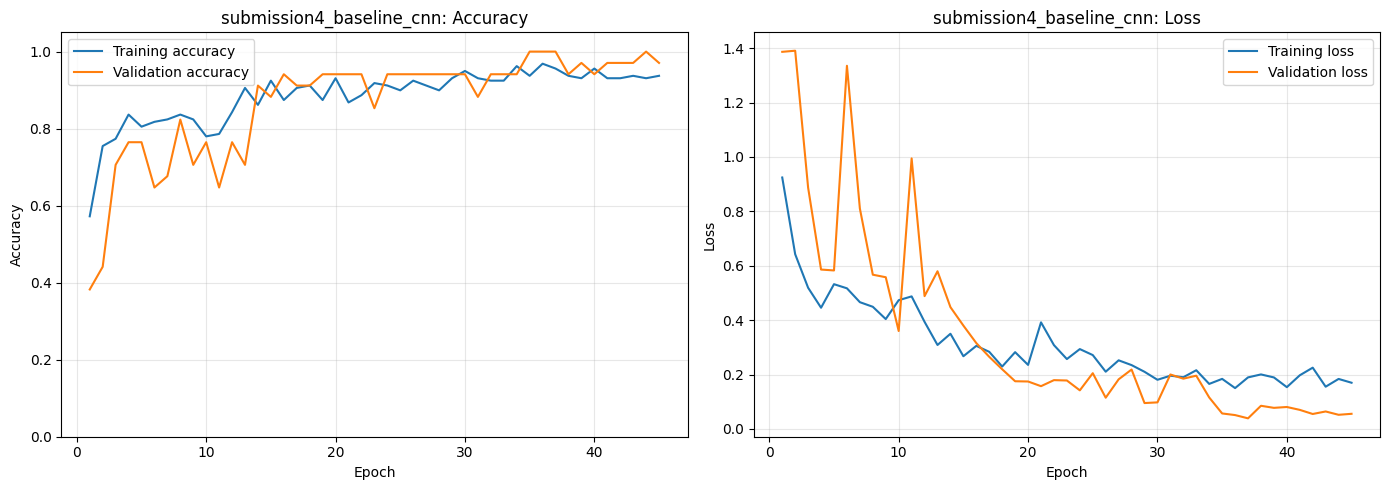


 submission4_baseline_cnn TEST CLASSIFICATION REPORT
                             precision    recall  f1-score   support

Cassava CB (Cassava Blight)       0.75      0.86      0.80         7
Cassava CM (Cassava Mosaic)       1.00      0.79      0.88        14
       Cassava Healthy leaf       0.88      1.00      0.93        14

                   accuracy                           0.89        35
                  macro avg       0.88      0.88      0.87        35
               weighted avg       0.90      0.89      0.89        35

Test accuracy: 0.8857
Macro precision: 0.8750
Macro recall: 0.8810
Macro F1: 0.8711
Weighted F1: 0.8853
Testing time (warm-up excluded): 0.3379 seconds


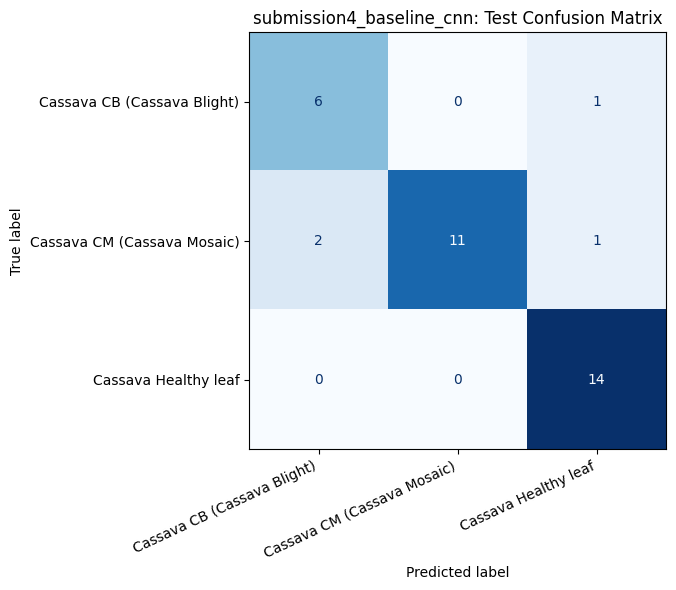


BEST CHECKPOINT: /content/drive/MyDrive/Cassava_CNN_Project/Submission_4_Results/checkpoints/submission4_baseline_cnn_best.pth
Epochs completed: 45
Best epoch: 37
Training time: 108.94 seconds

Training the same CNN with SE attention...
Starting submission4_se_attention_cnn: max 50 epochs, early stopping patience 8.
Epoch 01/50 | train loss 0.8401 | val loss 1.3690 | train acc 0.5723 | val acc 0.3824 | lr 0.001
Epoch 02/50 | train loss 0.6308 | val loss 1.2549 | train acc 0.7421 | val acc 0.5882 | lr 0.001
Epoch 03/50 | train loss 0.5106 | val loss 0.7315 | train acc 0.8113 | val acc 0.7353 | lr 0.001
Epoch 04/50 | train loss 0.4334 | val loss 0.4771 | train acc 0.8491 | val acc 0.7647 | lr 0.001
Epoch 05/50 | train loss 0.4937 | val loss 0.6721 | train acc 0.8239 | val acc 0.7941 | lr 0.001
Epoch 06/50 | train loss 0.5305 | val loss 1.0608 | train acc 0.8239 | val acc 0.7059 | lr 0.001
Epoch 07/50 | train loss 0.4697 | val loss 1.0079 | train acc 0.7862 | val acc 0.6765 | lr 0.001
Ep

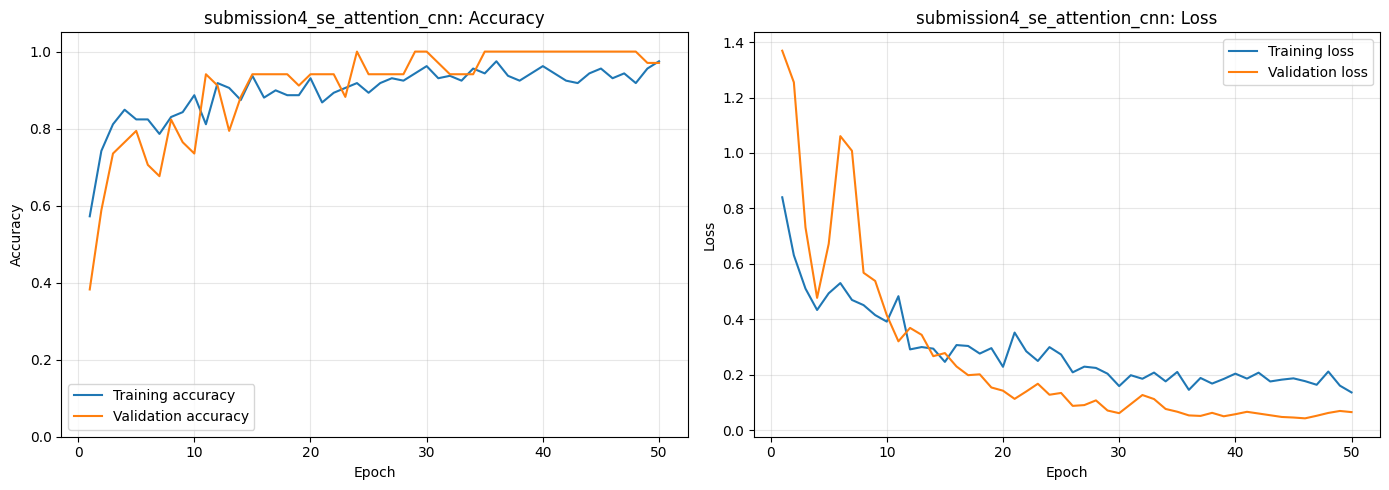


 submission4_se_attention_cnn TEST CLASSIFICATION REPORT
                             precision    recall  f1-score   support

Cassava CB (Cassava Blight)       0.86      0.86      0.86         7
Cassava CM (Cassava Mosaic)       1.00      0.86      0.92        14
       Cassava Healthy leaf       0.88      1.00      0.93        14

                   accuracy                           0.91        35
                  macro avg       0.91      0.90      0.90        35
               weighted avg       0.92      0.91      0.91        35

Test accuracy: 0.9143
Macro precision: 0.9107
Macro recall: 0.9048
Macro F1: 0.9045
Weighted F1: 0.9140
Testing time (warm-up excluded): 0.3092 seconds


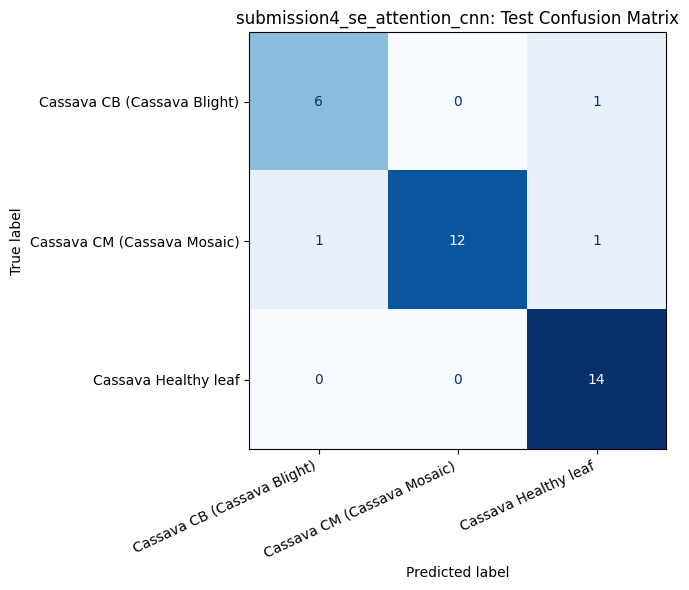


BEST CHECKPOINT: /content/drive/MyDrive/Cassava_CNN_Project/Submission_4_Results/checkpoints/submission4_se_attention_cnn_best.pth
Epochs completed: 50
Best epoch: 46
Training time: 96.16 seconds


In [7]:
S3_OUTPUT_DIR = PROJECT_DIR / 'Submission_3_Results'
S3_BASELINE_CHECKPOINT = S3_OUTPUT_DIR / 'checkpoints' / 'custom_cnn_baseline_best.pth'
if not S3_BASELINE_CHECKPOINT.exists():
    raise FileNotFoundError(
        'Submission 3 best checkpoint was not found. Complete Submission 3 first. Expected: '
        + str(S3_BASELINE_CHECKPOINT)
    )

S3_INITIAL_WEIGHTS = S3_OUTPUT_DIR / 'checkpoints' / 'custom_cnn_initial_weights.pth'
if not S3_INITIAL_WEIGHTS.exists():
    raise FileNotFoundError(
        'Submission 3 initial-weight file was not found. Re-run the Submission 3 notebook '
        'with the provided version so it saves custom_cnn_initial_weights.pth.'
    )

initial_state = torch.load(S3_INITIAL_WEIGHTS, map_location='cpu', weights_only=True)

set_seed(SEED)
baseline_model = CustomCNNWithOptionalSE(NUM_CLASSES, use_se=False)
se_model = CustomCNNWithOptionalSE(NUM_CLASSES, use_se=True)

base_state = baseline_model.state_dict()
se_state = se_model.state_dict()
for key, value in initial_state.items():
    if key in base_state and base_state[key].shape == value.shape:
        base_state[key] = value.clone()
    if key in se_state and se_state[key].shape == value.shape:
        se_state[key] = value.clone()

baseline_model.load_state_dict(base_state)
se_model.load_state_dict(se_state)

def run_submission4_variant(model, run_name):
    return train_custom_model(
        model=model,
        run_name=run_name,
        initial_state_path=None,
    )

print('Training baseline CNN under Submission 4 comparison settings...')
set_seed(SEED)
baseline_model, s4_baseline_result, s4_baseline_history = run_submission4_variant(
    baseline_model, 'submission4_baseline_cnn'
)

print('\nTraining the same CNN with SE attention...')
set_seed(SEED)
se_model, s4_se_result, s4_se_history = run_submission4_variant(
    se_model, 'submission4_se_attention_cnn'
)